# 01 — Exploratory Data Analysis (AI4I 2020)

**Goal:** understand the data *before* modelling — class balance, which signals separate failures
from normal operation, and what could leak the answer.

> Rule for this project: the failure-mode flags (`twf, hdf, pwf, osf, rnf`) and the ids are used
> **for EDA only**. They are never model inputs (see `docs/DATA.md`).

Data is loaded with `src.data.load_raw()`; column names are snake_case.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make `import src` work when the notebook runs from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src import config
from src.data import load_raw

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})
PALETTE = {0: "#4C78A8", 1: "#E4572E"}  # normal = blue, failure = red-orange
TARGET, SENSORS = config.TARGET_COLUMN, config.NUMERIC_SENSOR_COLUMNS
FLAGS = config.LEAKAGE_COLUMNS
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name: str) -> None:
    """Save the current figure to reports/figures/ (png, 150 dpi)."""
    plt.savefig(config.FIGURES_DIR / f"{name}.png", dpi=150)


df = load_raw()

## 1. Overview
**What:** shape, dtypes, first rows, summary statistics, missing values.
**Why:** catch obvious problems (wrong types, nulls, odd scales) before any analysis.

In [3]:
print("shape:", df.shape)
print("missing values:", int(df.isna().sum().sum()), "| duplicate udi:", int(df["udi"].duplicated().sum()))
df.dtypes.to_frame("dtype").T

shape: (10000, 14)
missing values: 0 | duplicate udi: 0


,udi,product_id,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
dtype,int64,object,object,float64,float64,int64,float64,int64,int64,int64,int64,int64,int64,int64


In [4]:
df.head()

,udi,product_id,type,air_temperature_k,process_temperature_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,twf,hdf,pwf,osf,rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df[SENSORS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
air_temperature_k,10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
process_temperature_k,10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
rotational_speed_rpm,10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
torque_nm,10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
tool_wear_min,10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0


In [6]:
df["type"].value_counts(normalize=True).round(3).to_frame("share")

,share
type,
L,0.6
M,0.3
H,0.1


## 2. Target imbalance
**What:** how many rows are failures. **Why:** a heavily imbalanced target decides which metrics
and training tricks we can use.

**Why accuracy is misleading:** if only ~3.4 % of rows are failures, a model that *always predicts
"no failure"* scores ~96.6 % accuracy while catching **zero** failures. Accuracy rewards the
majority class, so we report PR-AUC, recall, precision and F1/F2 instead.

machine_failure
0    9661
1     339
failure rate: 3.39% | 'always normal' baseline accuracy: 96.61%, recall: 0%


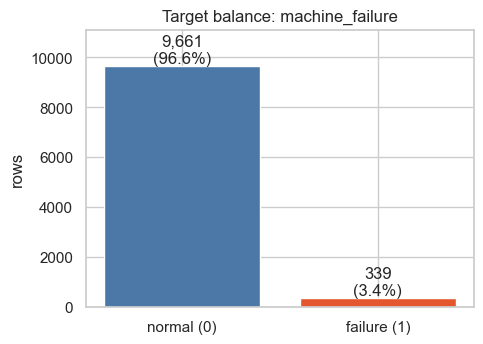

In [7]:
counts = df[TARGET].value_counts().sort_index()
rate = df[TARGET].mean()
print(counts.to_string())
print(f"failure rate: {rate:.2%} | 'always normal' baseline accuracy: {1 - rate:.2%}, recall: 0%")

fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(["normal (0)", "failure (1)"], counts.values, color=[PALETTE[0], PALETTE[1]])
ax.bar_label(bars, labels=[f"{n:,}\n({n / len(df):.1%})" for n in counts.values])
ax.set(ylabel="rows", title="Target balance: machine_failure", ylim=(0, counts.max() * 1.15))
save_fig("01_target_imbalance")
plt.show()

## 3. Failure modes (EDA only!)
**What:** the five flags say *how* a machine failed (tool wear, heat dissipation, power, overstrain,
random). **Why look:** to understand what generates the target and to prove they must not be used.

> ⚠️ **LEAKAGE.** `machine_failure` is (almost) the OR of these flags. They are known only *after*
> the failure happened, so using them as features would give a fake near-perfect score and a model
> that is useless in production. They stay out of the model — this section is exploration only.

In [8]:
print(df[FLAGS].sum().rename("rows with flag = 1").to_frame().T.to_string())

any_flag = df[FLAGS].sum(axis=1) > 0
fail = df[TARGET] == 1
print("\nfailures (machine_failure=1):", int(fail.sum()))
print("  ... without any mode flag :", int((fail & ~any_flag).sum()))
print("mode flag set but machine_failure=0:", int((~fail & any_flag).sum()))
print("  by flag:", df.loc[~fail & any_flag, FLAGS].sum().to_dict())

                    twf  hdf  pwf  osf  rnf
rows with flag = 1   46  115   95   98   19

failures (machine_failure=1): 339
  ... without any mode flag : 9
mode flag set but machine_failure=0: 18
  by flag: {'twf': 0, 'hdf': 0, 'pwf': 0, 'osf': 0, 'rnf': 18}


In [9]:
# Do the modes overlap? (several flags on one failure)
df.loc[fail, FLAGS].sum(axis=1).value_counts().sort_index().rename("failures with N flags").to_frame().T

,0,1,2,3
failures with N flags,9,306,23,1


**Reading the result:** the flags explain almost every failure, which is exactly why they leak.
A few failures have *no* flag, and a few `rnf` (random failure) rows are flagged yet
`machine_failure=0` — the dataset's own labels are slightly inconsistent, so a perfect score is
neither expected nor realistic.

## 4. Univariate distributions by outcome
**What:** histogram + KDE of each sensor, normal vs failure (densities, so the small failure class
is comparable). **Why:** a sensor whose two curves differ is a candidate signal.

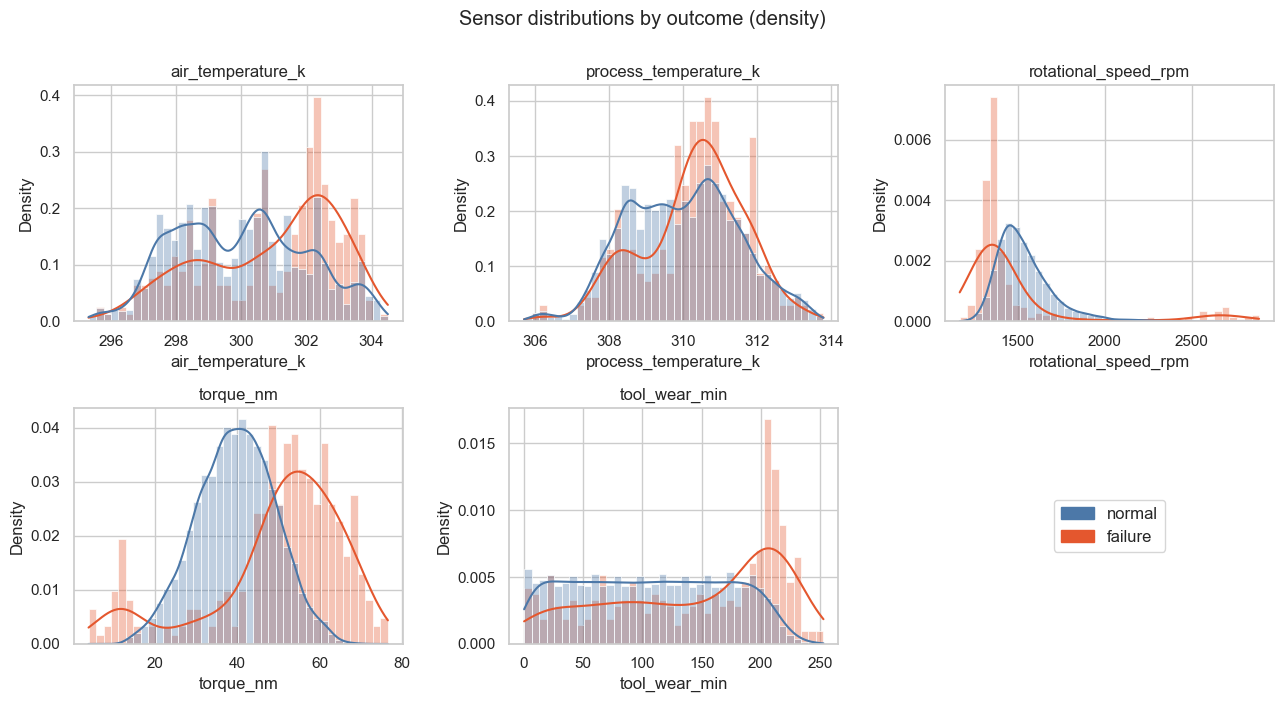

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, SENSORS):
    sns.histplot(data=df, x=col, hue=TARGET, palette=PALETTE, stat="density",
                 common_norm=False, kde=True, bins=40, alpha=0.35, ax=ax, legend=False)
    ax.set_title(col)
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PALETTE[k]) for k in (0, 1)],
                     labels=["normal", "failure"], loc="center", fontsize=12)
fig.suptitle("Sensor distributions by outcome (density)", y=1.0)
fig.tight_layout()
save_fig("02_sensor_distributions")
plt.show()

## 5. Boxplots and failure rate per Type
**What:** boxplot per sensor (failure vs normal) and failure rate per product Type.
**Why:** boxplots show shifts in median/spread and outliers; the Type rate shows whether the
quality class matters.

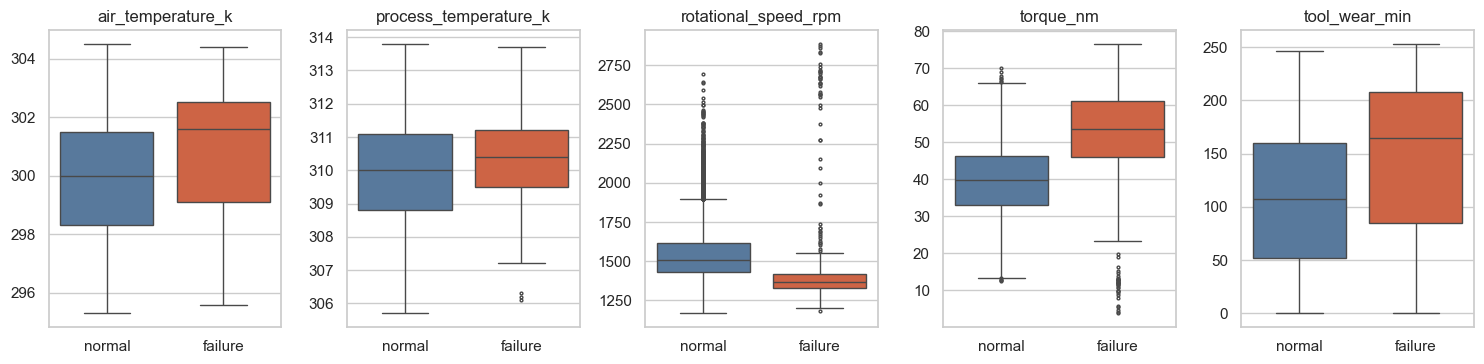

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for ax, col in zip(axes, SENSORS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=PALETTE, legend=False, ax=ax, fliersize=2)
    ax.set(xlabel="", xticks=[0, 1], xticklabels=["normal", "failure"], title=col)
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

,rows,failures,failure_rate
type,,,
L,6000,235,0.0392
M,2997,83,0.0277
H,1003,21,0.0209


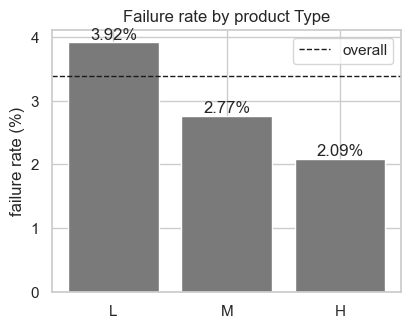

In [12]:
by_type = df.groupby("type")[TARGET].agg(rows="count", failures="sum", failure_rate="mean").loc[["L", "M", "H"]]
display(by_type.round(4))

fig, ax = plt.subplots(figsize=(4.5, 3.4))
bars = ax.bar(by_type.index, by_type["failure_rate"] * 100, color="#7A7A7A")
ax.bar_label(bars, fmt="%.2f%%")
ax.axhline(df[TARGET].mean() * 100, ls="--", c="k", lw=1, label="overall")
ax.set(ylabel="failure rate (%)", title="Failure rate by product Type")
ax.legend()
plt.show()

Type **L** (low quality, 60 % of rows) fails most often and **H** least — Type carries some signal,
but the differences are modest compared with the sensor effects. (Type shares are L 60 / M 30 / H 10 %,
not the 50/30/20 written in `DATA.md`.)

## 6. Correlation heatmap
**What:** Pearson correlations of the numeric sensors and the target. **Why:** spot redundant
features (multicollinearity) and linear links to failure. Pearson only sees *linear* relationships,
so weak values here do not rule out useful non-linear effects.

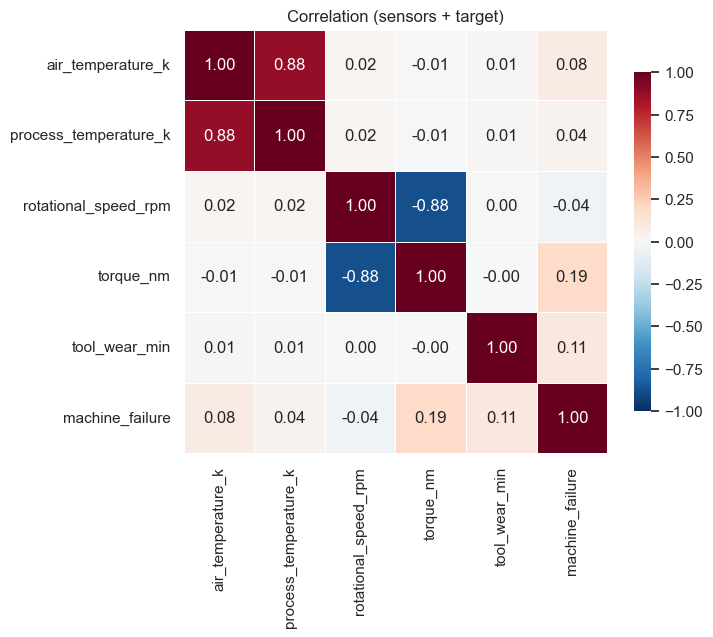

In [13]:
corr = df[SENSORS + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation (sensors + target)")
save_fig("03_correlation_heatmap")
plt.show()

Air and process temperature are strongly correlated (they move together with ambient conditions),
and torque is strongly *negatively* correlated with rotational speed (the machine trades speed for
torque). Against the target, torque and tool wear have the strongest linear links; both are modest.
This redundancy is why the *difference* of temperatures and the *product* of torque and speed
(see section 8) are interesting.

## 7. Bivariate views
**What:** torque vs rotational speed, and tool wear vs torque, coloured by outcome.
**Why:** failures may sit in specific *regions* (e.g. high torque at low speed) that no single
sensor reveals. Failures are plotted on top so the rare class stays visible.

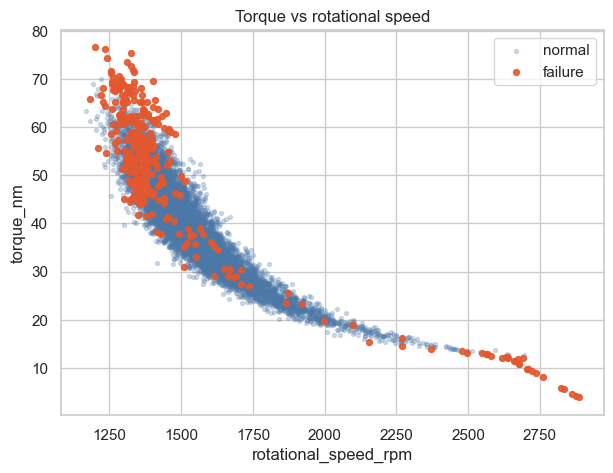

In [14]:
def scatter(ax, x, y):
    """Scatter normal rows faintly and failures on top."""
    for k, alpha, size in ((0, 0.25, 8), (1, 0.9, 18)):
        d = df[df[TARGET] == k]
        ax.scatter(d[x], d[y], s=size, alpha=alpha, color=PALETTE[k], label=["normal", "failure"][k])
    ax.set(xlabel=x, ylabel=y)


fig, ax = plt.subplots(figsize=(7, 5))
scatter(ax, "rotational_speed_rpm", "torque_nm")
ax.set_title("Torque vs rotational speed")
ax.legend()
save_fig("04_torque_vs_speed")
plt.show()

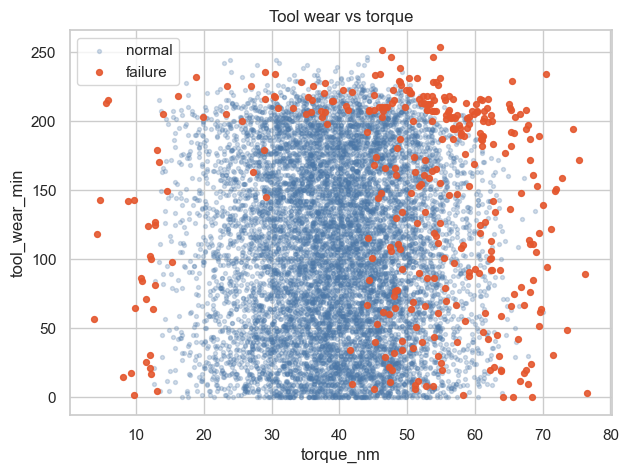

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
scatter(ax, "torque_nm", "tool_wear_min")
ax.set_title("Tool wear vs torque")
ax.legend()
plt.show()

Failures concentrate in two corners of the torque–speed plane: **low speed with high torque**, and
**high speed with low torque** (the curved boundary is roughly constant power). In the tool wear vs
torque plane, failures pile up at **high wear *and* high torque**. These are *interaction* effects —
the motivation for the engineered features below.

## 8. Planned engineered features (exploration only)
**What:** compute the three features from `docs/DATA.md` inline and compare them by outcome.
**Why:** check whether they separate the classes better than the raw sensors before we commit.

> 📝 Inline formulas are for **exploration only**. The real implementation lives in
> `src/features.py` (Phase 3) — one source of truth for training, API and dashboard.

In [16]:
eda = df.copy()  # throwaway copy; never fed to a model
eda["temp_diff_k"] = eda["process_temperature_k"] - eda["air_temperature_k"]
eda["power_w"] = eda["torque_nm"] * eda["rotational_speed_rpm"] * 2 * np.pi / 60
eda["strain"] = eda["tool_wear_min"] * eda["torque_nm"]
ENG = config.ENGINEERED_COLUMNS
eda.groupby(TARGET)[ENG].agg(["mean", "std", "min", "max"]).T.round(1)

machine_failure         0        1
temp_diff_k mean     10.0      9.4
            std       1.0      1.2
            min       7.6      7.6
            max      12.1     12.0
power_w     mean   6244.5   7282.8
            std    1011.4   1851.1
            min    3515.0   1148.4
            max    8998.0  10469.9
strain      mean   4213.8   7187.9
            std    2709.7   4234.0
            min       0.0      0.0
            max   11919.8  16497.0

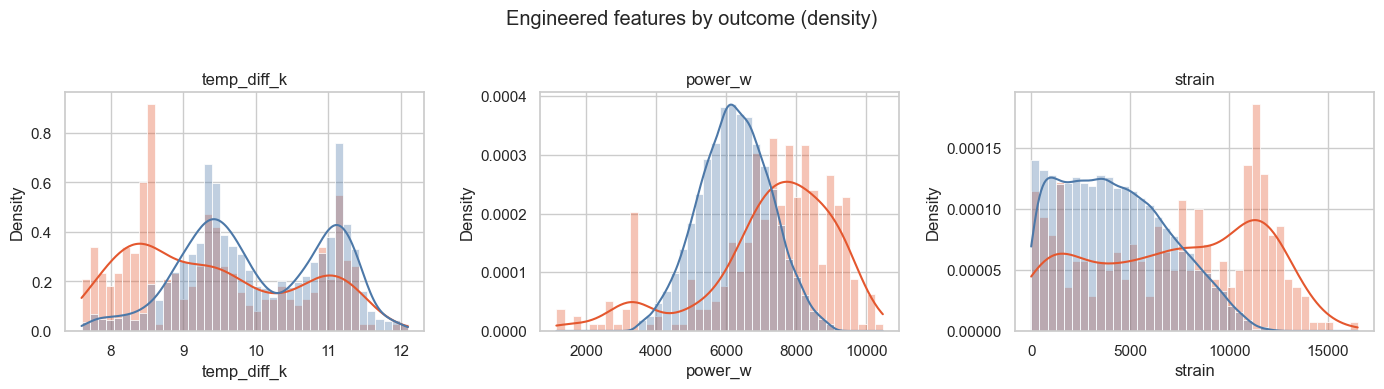

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ENG):
    sns.histplot(data=eda, x=col, hue=TARGET, palette=PALETTE, stat="density",
                 common_norm=False, kde=True, bins=40, alpha=0.35, ax=ax, legend=False)
    ax.set_title(col)
fig.suptitle("Engineered features by outcome (density)", y=1.02)
fig.tight_layout()
save_fig("05_engineered_features")
plt.show()

In [18]:
# How strongly does each feature relate to failure? (Pearson r with the target)
cols = SENSORS + ENG
eda[cols].corrwith(eda[TARGET]).sort_values(key=abs, ascending=False).round(3).to_frame("corr with failure")

,corr with failure
torque_nm,0.191
strain,0.190
power_w,0.176
temp_diff_k,-0.112
tool_wear_min,0.105
air_temperature_k,0.083
rotational_speed_rpm,-0.044
process_temperature_k,0.036


Failures shift to higher `strain` and higher, more spread-out `power_w` (both tails are risky: very
low power also fails), and to a smaller `temp_diff_k`. In plain linear correlation, though, `strain`
(0.19) and `power_w` (0.18) are no stronger than raw `torque_nm` (0.19), so their value is in
capturing *interactions* (torque x wear, torque x speed) that tree models can use directly and linear
models cannot. Heat-dissipation failures also need a small `temp_diff_k` *together with* low speed,
which a single correlation will not show. All three are kept for Phase 3.

## 9. Physical ranges in `src/config.py`
**What:** compare observed min/max with the validation ranges. **Why:** ranges are used by the data
validator and the API's input checks. They must contain every real value, yet be wide enough not to
reject plausible new readings.

In [19]:
rows = []
for col, (lo, hi) in config.VALUE_RANGES.items():
    rows.append({"feature": col, "observed_min": df[col].min(), "observed_max": df[col].max(),
                 "config_min": lo, "config_max": hi,
                 "margin_low": df[col].min() - lo, "margin_high": hi - df[col].max()})
ranges = pd.DataFrame(rows).set_index("feature")
display(ranges.round(1))
inside = all((df[c].between(*config.VALUE_RANGES[c])).all() for c in config.VALUE_RANGES)
print("all observed values inside config ranges:", inside)
print("process temp always above air temp:", bool((df["process_temperature_k"] > df["air_temperature_k"]).all()))

,observed_min,observed_max,config_min,config_max,margin_low,margin_high
feature,,,,,,
air_temperature_k,295.3,304.5,290.0,310.0,5.3,5.5
process_temperature_k,305.7,313.8,300.0,320.0,5.7,6.2
rotational_speed_rpm,1168.0,2886.0,1000.0,3000.0,168.0,114.0
torque_nm,3.8,76.6,0.0,100.0,3.8,23.4
tool_wear_min,0.0,253.0,0.0,300.0,0.0,47.0


all observed values inside config ranges: True
process temp always above air temp: True


**Decision:** every observed value lies inside the configured range, with a sensible safety margin on
both sides (about 5–10 K for temperatures, 168 rpm below and 114 rpm above for speed, 47 min above
for tool wear, and torque bounded at 0–100 Nm). The ranges are therefore **confirmed unchanged**.
They only guard against sensor glitches and typos; they are not a claim about the true physical
limits of the machine.

## 10. Key insights

1. **Severe class imbalance:** 339 of 10,000 rows (3.39 %) are failures. An "always normal" model gets 96.6 % accuracy with 0 % recall, so we judge models by PR-AUC, recall, precision and F1/F2, not accuracy.
2. **The data is clean:** no missing values, no duplicate ids, and every sensor lies inside the configured physical ranges (ranges confirmed, unchanged).
3. **Failure-mode flags are leakage:** `twf/hdf/pwf/osf/rnf` explain 330 of 339 failures (9 have no flag, and 18 `rnf` rows are flagged with `machine_failure=0`). They are known only after the failure, so they are excluded from the model.
4. **No single sensor separates the classes:** the strongest linear links to failure are torque (r = 0.19) and tool wear (r = 0.11). The sensor distributions overlap heavily, so a model must combine signals.
5. **Failures sit in specific regions:** low speed with high torque, high speed with low torque, and high tool wear combined with high torque. Above 60 Nm, 42 % of rows fail (vs 3.4 % overall).
6. **Strong redundancy in the inputs:** air and process temperature (r = 0.88) and torque and speed (r = −0.88) are almost the same information. This motivates the engineered features `temp_diff_k`, `power_w` and `strain`.
7. **Engineered features look useful:** failures have a much higher `strain` and a wider `power_w` spread, and a lower `temp_diff_k`. On linear correlation alone they are no stronger than raw torque (r ≈ 0.18–0.19), so their value is in capturing interactions for non-linear models.
8. **Product type matters a little:** failure rate is 3.9 % for L, 2.8 % for M and 2.1 % for H. Type is a weak but usable feature. The real mix is L 60 / M 30 / H 10 %, not the 50/30/20 in `DATA.md`.